In [1]:
# ==================================================
#  ADVANCED NUMPY ANALYTICS
# ==================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load cleaned dataset
sales_data = np.load("../data/processed/cleaned_sales.npz")

# Extract required arrays
quantity_arr = sales_data["quantity"]
unitprice_arr = sales_data["unitprice"]
customer_id_arr = sales_data["customer_id"]
invoice_arr = sales_data["invoice"]
invoice_date_arr = sales_data["invoice_data"]

# Calculate transaction-line revenue
revenue = quantity_arr * unitprice_arr

print("========== DATA LOADING REPORT ==========")

print(f"Total Records: {len(revenue):,}")
print(f"Total Revenue: £{np.sum(revenue):,.2f}")
print(f"Average Revenue: £{np.mean(revenue):,.2f}")

print("\nDataset Loaded Successfully!")

========== DATA LOADING REPORT ==========
Total Records: 530,104
Total Revenue: £10,666,684.54
Average Revenue: £20.12

Dataset Loaded Successfully!


In [2]:
# ==================================================
#  Z-SCORE ANOMALY DETECTION
# ==================================================

# 1. Calculate revenue statistics
mean_revenue = np.mean(revenue)
std_revenue = np.std(revenue)

print("========== REVENUE STATISTICS ==========")

print(f"Mean Revenue: £{mean_revenue:,.2f}")
print(f"Standard Deviation: £{std_revenue:,.2f}")

# ==================================================
# 2. CALCULATE Z-SCORES
# ==================================================

if std_revenue == 0:
    z_scores = np.zeros_like(revenue, dtype=float)
else:
    z_scores = (revenue - mean_revenue) / std_revenue

# ==================================================
# 3. IDENTIFY ANOMALIES
# ==================================================

# Transactions with absolute Z-score greater than 3
anomaly_mask = np.abs(z_scores) > 3

# Extract unusual transaction-line revenues
anomalies = revenue[anomaly_mask]

print("\n========== ANOMALY DETECTION REPORT ==========")

print(f"Total Transaction Lines: {len(revenue):,}")
print(f"Total Potential Anomalies: {len(anomalies):,}")

print(
    f"Anomaly Percentage: "
    f"{len(anomalies) / len(revenue) * 100:.2f}%"
)

# ==================================================
# 4. DISPLAY TOP 10 ANOMALIES
# ==================================================

anomaly_indices = np.where(anomaly_mask)[0]

top_indices = anomaly_indices[
    np.argsort(revenue[anomaly_indices])[-10:][::-1]
]

print("\n========== TOP 10 HIGH-REVENUE ANOMALIES ==========")

for rank, index in enumerate(top_indices, start=1):

    print(
        f"{rank:2}. Revenue: £{revenue[index]:,.2f} "
        f"| Z-Score: {z_scores[index]:.2f}"
    )

========== REVENUE STATISTICS ==========
Mean Revenue: £20.12
Standard Deviation: £270.36

========== ANOMALY DETECTION REPORT ==========
Total Transaction Lines: 530,104
Total Potential Anomalies: 535
Anomaly Percentage: 0.10%

========== TOP 10 HIGH-REVENUE ANOMALIES ==========
 1. Revenue: £168,469.60 | Z-Score: 623.06
 2. Revenue: £77,183.60 | Z-Score: 285.41
 3. Revenue: £38,970.00 | Z-Score: 144.07
 4. Revenue: £13,541.33 | Z-Score: 50.01
 5. Revenue: £11,062.06 | Z-Score: 40.84
 6. Revenue: £8,142.75 | Z-Score: 30.04
 7. Revenue: £7,144.72 | Z-Score: 26.35
 8. Revenue: £6,539.40 | Z-Score: 24.11
 9. Revenue: £6,539.40 | Z-Score: 24.11
10. Revenue: £4,992.00 | Z-Score: 18.39


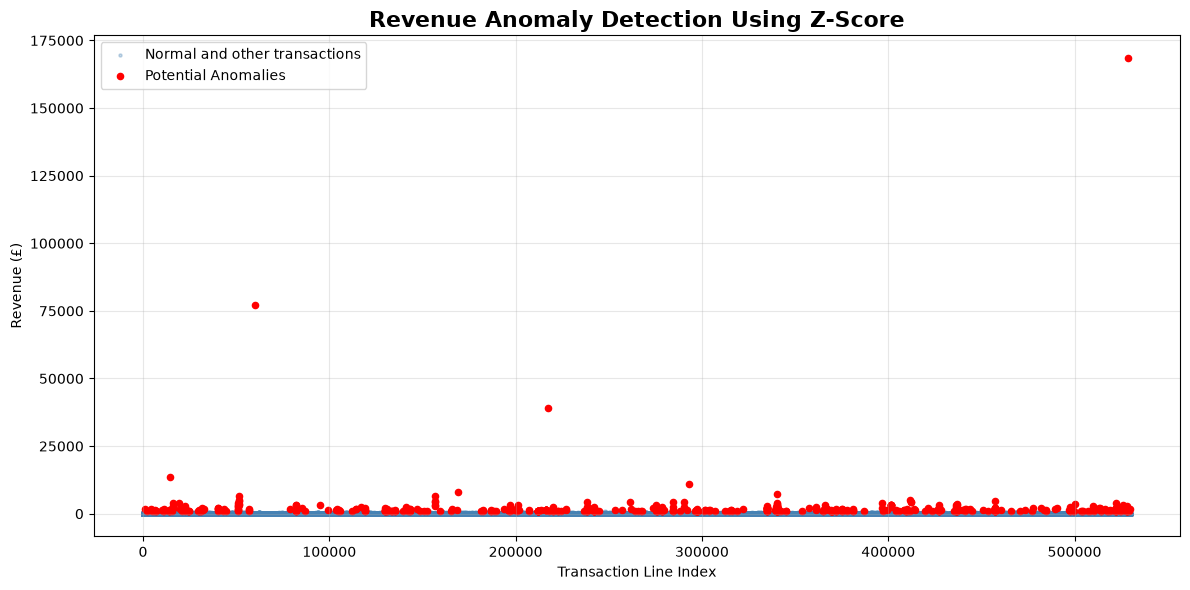

In [3]:
# ==================================================
# ANOMALY DETECTION VISUALIZATION
# ==================================================

plt.figure(figsize=(12, 6))

# Plot transaction-line revenues
plt.scatter(
    np.arange(len(revenue)),
    revenue,
    s=5,
    alpha=0.3,
    color="steelblue",
    label="Normal and other transactions"
)

# Highlight detected anomalies
plt.scatter(
    anomaly_indices,
    revenue[anomaly_indices],
    s=20,
    color="red",
    label="Potential Anomalies"
)

plt.title(
    "Revenue Anomaly Detection Using Z-Score",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Transaction Line Index")
plt.ylabel("Revenue (£)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

# Save chart
charts_dir = Path("../outputs/charts")
charts_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    charts_dir / "revenue_anomaly_detection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [4]:
# ==================================================
#  7-DAY MOVING AVERAGE ANALYSIS
# ==================================================

# 1. Convert invoice dates into daily format
invoice_days = invoice_date_arr.astype("datetime64[D]")

# 2. Identify unique transaction dates
unique_days, day_indices = np.unique(
    invoice_days,
    return_inverse=True
)

# 3. Calculate revenue for each date
daily_revenue = np.bincount(
    day_indices,
    weights=revenue
)

# ==================================================
# 4. INCLUDE MISSING CALENDAR DAYS
# ==================================================

# Create continuous date range
all_days = np.arange(
    unique_days.min(),
    unique_days.max() + np.timedelta64(1, "D"),
    dtype="datetime64[D]"
)

# Create daily revenue array
complete_daily_revenue = np.zeros(
    len(all_days),
    dtype=float
)

# Map transaction dates to calendar dates
day_positions = np.searchsorted(all_days, unique_days)

complete_daily_revenue[day_positions] = daily_revenue

# ==================================================
# 5. CALCULATE 7-DAY MOVING AVERAGE
# ==================================================

window_size = 7

# Create equal-weight moving average window
weights = np.ones(window_size) / window_size

# Calculate moving average
moving_average = np.convolve(
    complete_daily_revenue,
    weights,
    mode="valid"
)

# Align dates with moving average values
moving_average_dates = all_days[window_size - 1:]

# ==================================================
# 6. DISPLAY MOVING AVERAGE REPORT
# ==================================================

print("========== 7-DAY MOVING AVERAGE REPORT ==========")

print(f"Total Calendar Days: {len(all_days):,}")
print(f"Total Transaction Dates: {len(unique_days):,}")
print(f"Moving Average Records: {len(moving_average):,}")

print("\nFirst 10 Moving Average Values:")

for date, avg in zip(
    moving_average_dates[:10],
    moving_average[:10]
):
    print(f"{date} | 7-Day Average Revenue: £{avg:,.2f}")

========== 7-DAY MOVING AVERAGE REPORT ==========
Total Calendar Days: 374
Total Transaction Dates: 305
Moving Average Records: 368

First 10 Moving Average Values:
2010-12-07 | 7-Day Average Revenue: £48,553.78
2010-12-08 | 7-Day Average Revenue: £46,615.10
2010-12-09 | 7-Day Average Revenue: £47,449.07
2010-12-10 | 7-Day Average Revenue: £49,197.53
2010-12-11 | 7-Day Average Revenue: £49,197.53
2010-12-12 | 7-Day Average Revenue: £47,133.83
2010-12-13 | 7-Day Average Revenue: £44,730.44
2010-12-14 | 7-Day Average Revenue: £36,964.23
2010-12-15 | 7-Day Average Revenue: £34,829.18
2010-12-16 | 7-Day Average Revenue: £34,224.42


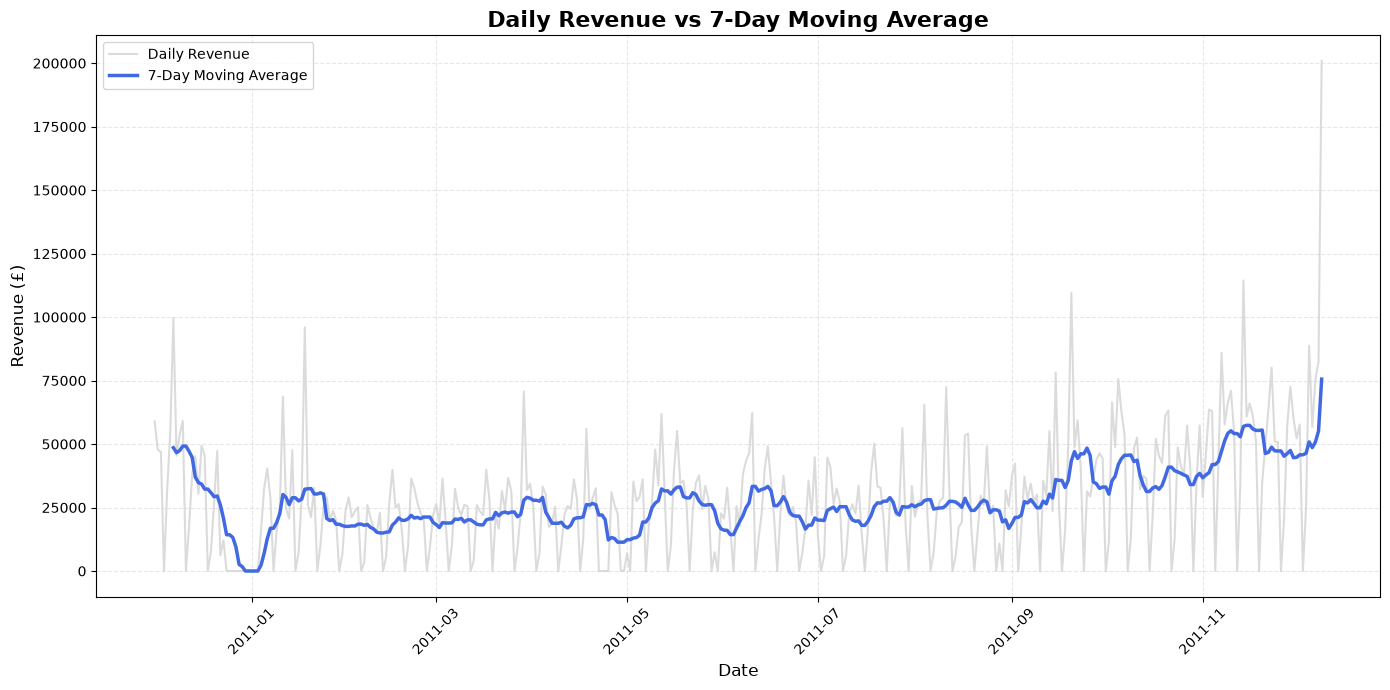

In [5]:
# ==================================================
# 7-DAY MOVING AVERAGE VISUALIZATION
# ==================================================

plt.figure(figsize=(14, 7))

# Plot daily revenue
plt.plot(
    all_days,
    complete_daily_revenue,
    label="Daily Revenue",
    color="lightgray",
    linewidth=1.5,
    alpha=0.8
)

# Plot 7-day moving average
plt.plot(
    moving_average_dates,
    moving_average,
    label="7-Day Moving Average",
    color="royalblue",
    linewidth=2.5
)

# Chart formatting
plt.title(
    "Daily Revenue vs 7-Day Moving Average",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date", fontsize=12)
plt.ylabel("Revenue (£)", fontsize=12)

plt.legend()
plt.grid(linestyle="--", alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()

# Save chart
charts_dir = Path("../outputs/charts")
charts_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    charts_dir / "7_day_moving_average.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [6]:
# ==================================================
# VERIFY MOVING AVERAGE
# ==================================================

# Check the first 7-day average manually
manual_average = np.mean(complete_daily_revenue[:7])

# Compare with NumPy convolution result
verified = np.isclose(
    manual_average,
    moving_average[0]
)

print("Manual Average:", manual_average)
print("Convolution Average:", moving_average[0])

print("Moving Average Verification:", verified)

Manual Average: 48553.78428571446
Convolution Average: 48553.784285714464
Moving Average Verification: True


In [7]:
# ==================================================
#  CUSTOMER SPENDING PERCENTILE ANALYSIS
# ==================================================

# 1. Remove records with missing CustomerIDs
valid_customer_mask = ~np.isnan(customer_id_arr)

valid_customer_ids = customer_id_arr[valid_customer_mask]
valid_revenue = revenue[valid_customer_mask]

# ==================================================
# 2. CALCULATE CUSTOMER-WISE SPENDING
# ==================================================

# Identify unique customers and their corresponding indexes
unique_customers, customer_indices = np.unique(
    valid_customer_ids,
    return_inverse=True
)

# Calculate total spending for each customer
customer_spending = np.bincount(
    customer_indices,
    weights=valid_revenue
)

# ==================================================
# 3. CALCULATE SPENDING PERCENTILES
# ==================================================

percentiles = [25, 50, 75, 90, 95, 99]

spending_percentiles = np.percentile(
    customer_spending,
    percentiles
)

print("========== CUSTOMER SPENDING PERCENTILES ==========")

for percentile, value in zip(percentiles, spending_percentiles):
    print(f"{percentile}th Percentile: £{value:,.2f}")

# ==================================================
# 4. IDENTIFY HIGH-VALUE CUSTOMERS
# ==================================================

# Customers at or above the 90th percentile
high_value_threshold = np.percentile(
    customer_spending,
    90
)

high_value_mask = customer_spending >= high_value_threshold

high_value_customers = unique_customers[high_value_mask]
high_value_spending = customer_spending[high_value_mask]

print("\n========== HIGH-VALUE CUSTOMERS ==========")

print(f"Total Customers: {len(unique_customers):,}")

print(f"High-Value Customers: {len(high_value_customers):,}")

print(f"Spending Threshold: £{high_value_threshold:,.2f}")

# ==================================================
# 5. CALCULATE HIGH-VALUE CUSTOMER REVENUE
# ==================================================

total_customer_revenue = np.sum(customer_spending)

high_value_revenue = np.sum(high_value_spending)

revenue_percentage = (
    high_value_revenue / total_customer_revenue * 100
)

print("\n========== HIGH-VALUE REVENUE REPORT ==========")

print(f"Total Identified Customer Revenue: £{total_customer_revenue:,.2f}")

print(f"High-Value Customer Revenue: £{high_value_revenue:,.2f}")

print(f"Revenue Contribution: {revenue_percentage:.2f}%")

========== CUSTOMER SPENDING PERCENTILES ==========
25th Percentile: £307.41
50th Percentile: £674.48
75th Percentile: £1,661.74
90th Percentile: £3,646.53
95th Percentile: £5,841.84
99th Percentile: £19,881.00

========== HIGH-VALUE CUSTOMERS ==========
Total Customers: 4,338
High-Value Customers: 434
Spending Threshold: £3,646.53

========== HIGH-VALUE REVENUE REPORT ==========
Total Identified Customer Revenue: £8,911,407.90
High-Value Customer Revenue: £5,469,382.46
Revenue Contribution: 61.38%


In [8]:
# ==================================================
# VERIFY CUSTOMER SPENDING ANALYSIS
# ==================================================

# 1. Verify customer spending calculation
spending_verified = np.isclose(
    np.sum(customer_spending),
    np.sum(valid_revenue)
)

# 2. Verify percentile order
percentile_verified = np.all(
    np.diff(spending_percentiles) >= 0
)

# 3. Verify high-value revenue
revenue_verified = (
    high_value_revenue <= total_customer_revenue
)

print("========== VERIFICATION REPORT ==========")

print("Customer Spending Verified:", spending_verified)
print("Percentile Order Verified:", percentile_verified)
print("High-Value Revenue Verified:", revenue_verified)

========== VERIFICATION REPORT ==========
Customer Spending Verified: True
Percentile Order Verified: True
High-Value Revenue Verified: True


In [9]:
# ==================================================
#  SALES CORRELATION ANALYSIS
# ==================================================

# 1. Prepare numerical arrays
quantity = quantity_arr.astype(float)
unitprice = unitprice_arr.astype(float)
sales_revenue = revenue.astype(float)

# ==================================================
# 2. CALCULATE INDIVIDUAL CORRELATIONS
# ==================================================

# Quantity vs Revenue
quantity_revenue_corr = np.corrcoef(
    quantity,
    sales_revenue
)[0, 1]

# UnitPrice vs Revenue
price_revenue_corr = np.corrcoef(
    unitprice,
    sales_revenue
)[0, 1]

# Quantity vs UnitPrice
quantity_price_corr = np.corrcoef(
    quantity,
    unitprice
)[0, 1]

# ==================================================
# 3. DISPLAY CORRELATION REPORT
# ==================================================

print("========== SALES CORRELATION REPORT ==========")

print(
    f"Quantity vs Revenue  : {quantity_revenue_corr:.4f}"
)

print(
    f"UnitPrice vs Revenue : {price_revenue_corr:.4f}"
)

print(
    f"Quantity vs UnitPrice: {quantity_price_corr:.4f}"
)

========== SALES CORRELATION REPORT ==========
Quantity vs Revenue  : 0.9073
UnitPrice vs Revenue : 0.1374
Quantity vs UnitPrice: -0.0038


In [10]:
# ==================================================
#  CREATE CORRELATION MATRIX
# ==================================================

# Combine numerical variables
sales_features = np.array([
    quantity,
    unitprice,
    sales_revenue
])

# Calculate correlation matrix
correlation_matrix = np.corrcoef(sales_features)

# Feature names
feature_names = [
    "Quantity",
    "UnitPrice",
    "Revenue"
]

print("\n========== CORRELATION MATRIX ==========")

print(correlation_matrix)


========== CORRELATION MATRIX ==========
[[ 1.         -0.00377254  0.90733778]
 [-0.00377254  1.          0.13740353]
 [ 0.90733778  0.13740353  1.        ]]


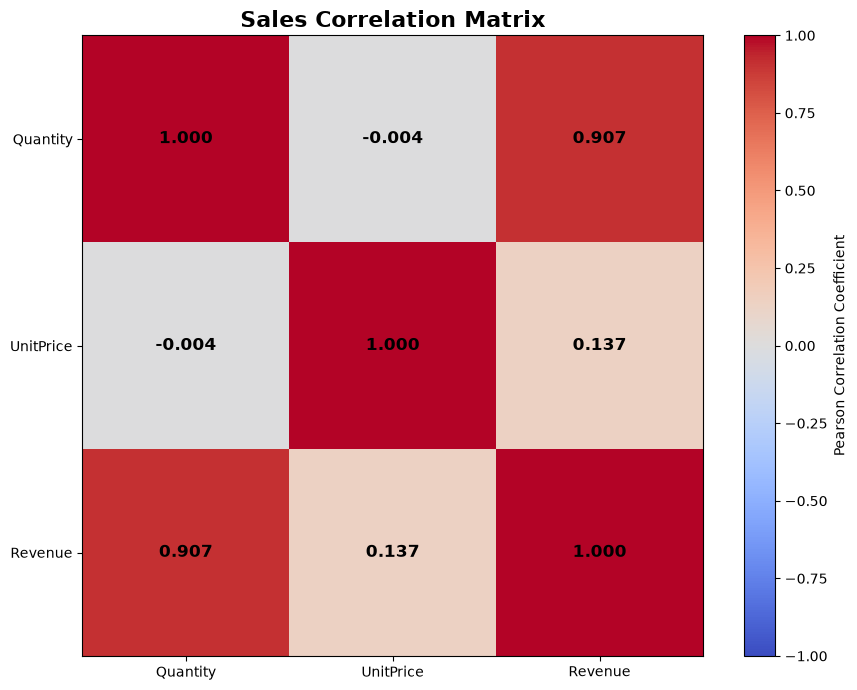

In [11]:
# ==================================================
#  CORRELATION HEATMAP
# ==================================================

plt.figure(figsize=(9, 7))

# Create heatmap
im = plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

# Add feature labels
plt.xticks(
    np.arange(len(feature_names)),
    feature_names
)

plt.yticks(
    np.arange(len(feature_names)),
    feature_names
)

# Display correlation values in each cell
for i in range(len(feature_names)):
    for j in range(len(feature_names)):

        value = correlation_matrix[i, j]

        plt.text(
            j,
            i,
            f"{value:.3f}",
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold"
        )

# Chart formatting
plt.title(
    "Sales Correlation Matrix",
    fontsize=16,
    fontweight="bold"
)

plt.colorbar(
    im,
    label="Pearson Correlation Coefficient"
)

plt.tight_layout()

# ==================================================
# SAVE HEATMAP
# ==================================================

charts_dir = Path("../outputs/charts")
charts_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    charts_dir / "sales_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
# ==================================================
# VERIFY CORRELATION MATRIX
# ==================================================

# Check matrix shape
shape_verified = correlation_matrix.shape == (3, 3)

# Check symmetry
symmetry_verified = np.allclose(
    correlation_matrix,
    correlation_matrix.T
)

# Check diagonal values
diagonal_verified = np.allclose(
    np.diag(correlation_matrix),
    1
)

# Check correlation range
range_verified = np.all(
    (correlation_matrix >= -1 - 1e-12)
    & (correlation_matrix <= 1 + 1e-12)
)

print("========== CORRELATION VERIFICATION ==========")

print("Matrix Shape Verified:", shape_verified)
print("Matrix Symmetry Verified:", symmetry_verified)
print("Diagonal Values Verified:", diagonal_verified)
print("Correlation Range Verified:", range_verified)

========== CORRELATION VERIFICATION ==========
Matrix Shape Verified: True
Matrix Symmetry Verified: True
Diagonal Values Verified: True
Correlation Range Verified: True


In [13]:
# ==================================================
# LINEAR REGRESSION: DATA PREPARATION
# ==================================================

# Convert days into numerical values
X = np.arange(len(complete_daily_revenue))

# Target variable: daily revenue
y = complete_daily_revenue

print("Total Days:", len(X))
print("Total Revenue Records:", len(y))

print("First 5 Days:", X[:5])
print("First 5 Revenue Values:", y[:5])

Total Days: 374
Total Revenue Records: 374
First 5 Days: [0 1 2 3 4]
First 5 Revenue Values: [58960.79 47748.38 46943.71     0.   31774.95]


In [14]:
# ==================================================
# TRAIN / TEST SPLIT
# ==================================================

split_index = int(len(X) * 0.8)

X_train = X[:split_index]
X_test = X[split_index:]

y_train = y[:split_index]
y_test = y[split_index:]

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 299
Testing Records: 75


In [15]:
# ==================================================
# TRAIN LINEAR REGRESSION MODEL
# ==================================================

# Create design matrix
X_train_matrix = np.column_stack([
    X_train,
    np.ones(len(X_train))
])

# Calculate slope and intercept
coefficients = np.linalg.lstsq(
    X_train_matrix,
    y_train,
    rcond=None
)[0]

slope, intercept = coefficients

print("========== MODEL PARAMETERS ==========")
print(f"Slope: {slope:.4f}")
print(f"Intercept: {intercept:.4f}")

========== MODEL PARAMETERS ==========
Slope: 19.1607
Intercept: 21102.4191


In [16]:
# ==================================================
# MODEL PREDICTION AND EVALUATION
# ==================================================

# Predict revenue for testing days
y_pred = slope * X_test + intercept

# Calculate Mean Absolute Error
mae = np.mean(np.abs(y_test - y_pred))

# Calculate Root Mean Squared Error
rmse = np.sqrt(np.mean((y_test - y_pred) ** 2))

print("========== MODEL EVALUATION ==========")
print(f"Mean Absolute Error: £{mae:,.2f}")
print(f"Root Mean Squared Error: £{rmse:,.2f}")

========== MODEL EVALUATION ==========
Mean Absolute Error: £28,140.85
Root Mean Squared Error: £35,995.95


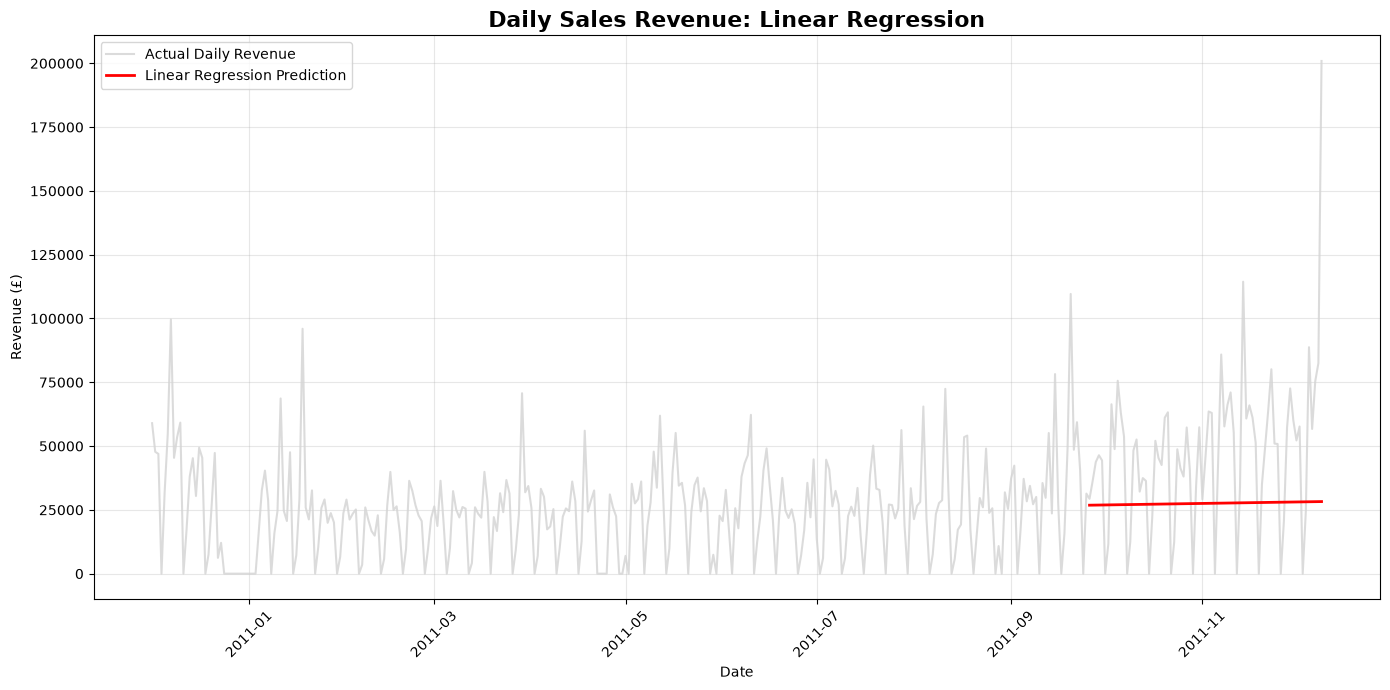

In [17]:
# ==================================================
# LINEAR REGRESSION VISUALIZATION
# ==================================================

plt.figure(figsize=(14, 7))

# Actual daily revenue
plt.plot(
    all_days,
    y,
    label="Actual Daily Revenue",
    color="lightgray",
    alpha=0.8
)

# Predicted revenue for test period
plt.plot(
    all_days[split_index:],
    y_pred,
    label="Linear Regression Prediction",
    color="red",
    linewidth=2
)

plt.title(
    "Daily Sales Revenue: Linear Regression",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Revenue (£)")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()

# Save chart
charts_dir = Path("../outputs/charts")
charts_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    charts_dir / "linear_regression_prediction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
# ==================================================
# EXPERIMENTAL 7-DAY REVENUE FORECAST
# ==================================================

# Retrain on all available days
X_full_matrix = np.column_stack([
    X,
    np.ones(len(X))
])

full_coefficients = np.linalg.lstsq(
    X_full_matrix,
    y,
    rcond=None
)[0]

full_slope, full_intercept = full_coefficients

# Create next 7 day indexes
future_days = np.arange(
    len(X),
    len(X) + 7
)

# Generate estimated revenue
future_predictions = (
    full_slope * future_days + full_intercept
)

# Generate corresponding future dates
future_dates = (
    all_days[-1]
    + np.arange(1, 8).astype("timedelta64[D]")
)

print("========== NEXT 7-DAY EXPERIMENTAL FORECAST ==========")

for date, prediction in zip(future_dates, future_predictions):
    print(f"{date} | Estimated Revenue: £{prediction:,.2f}")

========== NEXT 7-DAY EXPERIMENTAL FORECAST ==========
2011-12-10 | Estimated Revenue: £42,003.30
2011-12-11 | Estimated Revenue: £42,075.21
2011-12-12 | Estimated Revenue: £42,147.11
2011-12-13 | Estimated Revenue: £42,219.02
2011-12-14 | Estimated Revenue: £42,290.93
2011-12-15 | Estimated Revenue: £42,362.84
2011-12-16 | Estimated Revenue: £42,434.75
